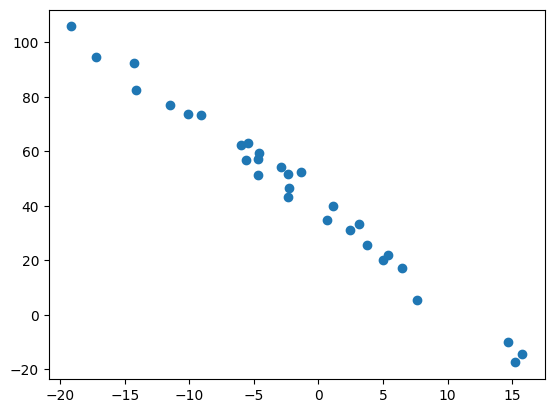

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## Our Data
n = 30
np.random.seed(42) # Added for reproducible results

x = 10*np.random.randn(n)
y = -3.5*x + 40 + 4*np.random.randn(n)

plt.scatter(x,y)


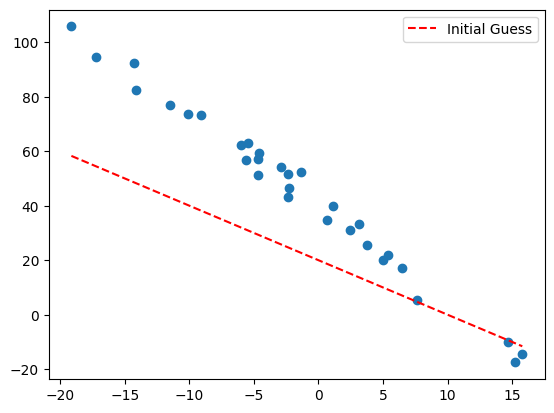

In [16]:
# Initial parameters. T[0] is for the y-intercept, T[1] for the slope.

T = [20.0, -2.0]

plt.scatter(x,y)
x_line = np.linspace(x.min(), x.max(), 100)

# Plot Initial Line
y_line_initial = T[0] + T[1] * x_line#_norm
plt.plot(x_line, y_line_initial, color='red', linestyle='--', label='Initial Guess')
plt.legend()
plt.show()


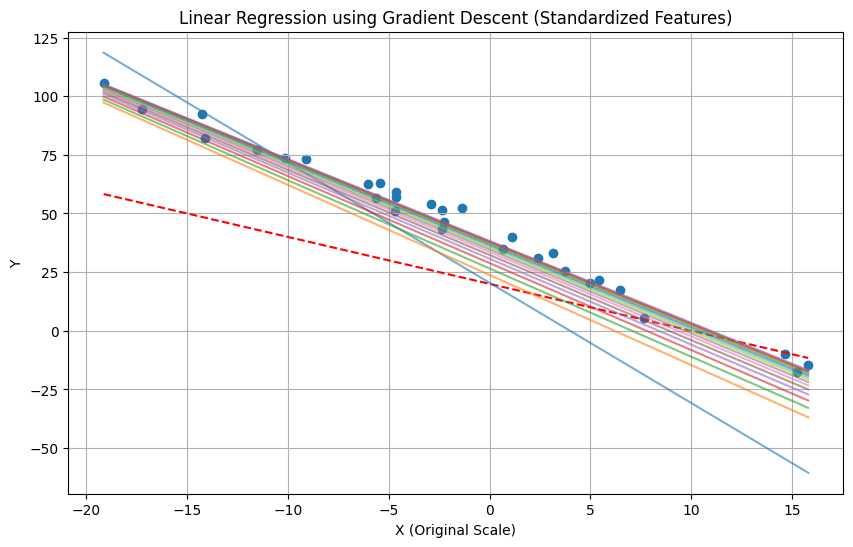

In [17]:

def refine_reg(T, X, Y, lrate=0.01):
    n = len(X)
    # The error calculation is correct for MSE cost function
    error = T[0] + T[1]*X - Y
    
    # Gradient for T[0] (y-intercept/bias)
    dE0 = 2 * np.sum(error) / n
    
    # Gradient for T[1] (slope/weight)
    dE1 = 2 * X.dot(error) / n
    
    T[0] -= lrate * dE0
    T[1] -= lrate * dE1
    return T

# Prepare the plot
plt.figure(figsize=(10, 6))
plt.scatter(x, y, label='Data Points')
x_line = np.linspace(x.min(), x.max(), 100)

# Plot Initial Line
y_line_initial = T[0] + T[1] * x_line
plt.plot(x_line, y_line_initial, color='red', linestyle='--', label='Initial Guess')

# Run Gradient Descent
for i in range(150):
    # Pass the standardized data (x_norm) to the refinement function
    T = refine_reg(T, x, y, lrate=0.01) # Increased lrate for faster convergence
    
    # Plot the line for the iteration
    y_line = T[0] + T[1] * x_line
    if i%10 == 0:
        plt.plot(x_line, y_line, alpha=0.6, label=f"Iter {i+1}" if i%10 == 0 else None)


plt.title('Linear Regression using Gradient Descent (Standardized Features)')
plt.xlabel('X (Original Scale)')
plt.ylabel('Y')
# plt.legend(loc='lower left')
plt.grid(True)
plt.show()

How does the Gradient Descent method compare to the actual calculation?

In [18]:
# Print from Gradient Descent Method
print(f"Gradient Descent results: {T}")

# Calculate parameters using Linear Regression
r = ((x-np.mean(x))*(y-np.mean(y))).sum() / (x.std() * y.std() * len(x))
slope = r * (np.std(y) / np.std(x))
intercept = np.mean(y) - slope * np.mean(x)

print(f"Linear Regression results: Intercept = {intercept}, Slope = {slope}")

Gradient Descent results: [np.float64(38.51293861172855), np.float64(-3.48420772643647)]
Linear Regression results: Intercept = 39.59230111508883, Slope = -3.4591005762276756


In [5]:
T[1]/x.std()

np.float64(-3.3029556264837816)

In [6]:
T[0] - (T[1] * np.mean(x) / np.std(x))

np.float64(38.62553310038439)